# Exercise 1: Markowitz Portfolio Optimization

In [ ]:
%pip install pyscipopt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
import yfinance as yf
import seaborn as sns
from scipy.interpolate import interp1d

plt.style.use("ggplot")

## Simulated Data

### Exercise 1: Calculating the Minimum-Risk Portfolio

**Objective**: Minimize portfolio risk.

#### Data:
- **Expected Returns**: An array `retornos_esperados` containing the expected return of each asset.
- **Covariance Matrix**: `matriz_cov`, describing the covariance between assets and their combined risk.

#### Constraints:
1. Short selling is not allowed.

Remember that portfolio variance, $ \sigma^2_p $, is calculated as:

$ \qquad \qquad \sigma^2_p = w^T \Sigma w $

where:
- $ w $ is the vector of portfolio weights. Each element $ w_i $ represents the fraction of total capital invested in asset $ i $.
- $ \Sigma $ is the covariance matrix of asset returns. Each element $ \sigma_{ij} $ represents the covariance between the returns of assets $ i $ and $ j $.

In [2]:
# Return and covariance data

retornos_esperados = np.array([0.17, 0.10, 0.07, 0.09])  # Example expected returns

matriz_cov = np.array(
    [
        [1.83977374, 1.23002575, 1.59282297, 0.69409837],
        [1.23002575, 1.45345954, 1.7548078, 1.31477996],
        [1.59282297, 1.7548078, 2.14425197, 1.55568552],
        [0.69409837, 1.31477996, 1.55568552, 1.46502412],
    ]
)

In [3]:
# Decision variable: the portfolio has four weights for four assets
pesos = cp.Variable(4)

In `cvxpy`, `cp.quad_form(x, P)` takes two arguments:

- `x`: A variable or vector of variables in the optimization problem.
- `P`: A matrix specifying how the variables in `x` are combined in the quadratic form.

The resulting quadratic form is $x^T P x$, where $x^T$ denotes the transpose of vector `x` and `P` is the given matrix.

**Example in two dimensions**

Suppose that:
$$
x = \begin{bmatrix} x_1 \\ x_2 \end{bmatrix}, \quad
P = \begin{bmatrix} p_{11} & p_{12} \\ p_{12} & p_{22} \end{bmatrix}
$$
Then:
$$
x^T P x = \begin{bmatrix} x_1 & x_2 \end{bmatrix}
\begin{bmatrix} p_{11} & p_{12} \\ p_{12} & p_{22} \end{bmatrix}
\begin{bmatrix} x_1 \\ x_2 \end{bmatrix}
$$
Expanding the product:
$$
x_1 p_{11} x_1 + x_1 p_{12} x_2 + x_2 p_{12} x_1 + x_2 p_{22} x_2
$$
This can be rewritten as:
$$
p_{11} x_1^2 + p_{22} x_2^2 + 2 p_{12} x_1 x_2
$$
This is a quadratic expression in $x_1$ and $x_2$, since its terms have degree at most 2.

In [4]:
# Objective function
riesgo = cp.quad_form(pesos, matriz_cov)  # w^T @ Sigma @ w -> Returns variance
objetivo = cp.Minimize(riesgo)

In [5]:
# Constraints
constraints = [cp.sum(pesos) == 1, pesos >= 0]

In [6]:
# Optimization problem
problema = cp.Problem(objetivo, constraints)

# Solving the problem
resultado = problema.solve()

# Results
pesos_optimos = pesos.value

In [7]:
varianza = riesgo.value
volatilidad = np.sqrt(varianza)

print(f"Portfolio risk is: {volatilidad:.2f}")


print(
    f"Portfolio return is: {100*(retornos_esperados @ pesos_optimos).round(4)}%"
)


print(
    f"The portfolio weights that minimize risk are: {100*pesos_optimos.round(2)}"
)

Portfolio risk is: 1.07
Portfolio return is: 12.22%
The portfolio weights that minimize risk are: [40. -0. -0. 60.]


### Additional Questions
- Solve the previous problem with an additional minimum-return requirement of 14%.

In [8]:
# Constraints
constraints = [cp.sum(pesos) == 1, pesos >= 0, retornos_esperados @ pesos >= 0.14]

In [9]:
# Optimization problem
problema = cp.Problem(objetivo, constraints)

# Solving the problem
resultado = problema.solve()

# Results
pesos_optimos = pesos.value

In [10]:
varianza = riesgo.value
volatilidad = np.sqrt(varianza)

print(f"Portfolio risk is: {volatilidad:.2f}")
print(
    f"Portfolio return is: {100*(retornos_esperados @ pesos_optimos).round(4)}%"
)
print(
    f"The portfolio weights that minimize risk are: {100*pesos_optimos.round(2)}"
)

Portfolio risk is: 1.12
Portfolio return is: 14.000000000000002%
The portfolio weights that minimize risk are: [63.  0.  0. 38.]


- What if the minimum required return is 18%?

In [11]:
# Constraints
constraints = [cp.sum(pesos) == 1, pesos >= 0, retornos_esperados @ pesos >= 0.18]

# Optimization problem
problema = cp.Problem(objetivo, constraints)

# Solving the problem
resultado = problema.solve()

# Results
pesos_optimos = pesos.value

In [12]:
print(
    f"The portfolio weights that minimize risk are: {100*pesos_optimos.round(2)}"
)

AttributeError: 'NoneType' object has no attribute 'round'

In [14]:
# Check whether an optimal solution was found
if problema.status == cp.OPTIMAL:
    # Results
    pesos_optimos = pesos.value
    print(f"Optimization successful. Optimal value: {resultado}")
else:
    print(f"Could not find una solución óptima. Estado: {problema.status}")
    if problema.status == cp.INFEASIBLE:
        print(
            "El problema es infactible. Las restricciones no pueden satisfacerse simultáneamente."
        )
    elif problema.status == cp.UNBOUNDED:
        print(
            "El problema es no acotado. La función objetivo puede mejorarse indefinidamente."
        )
    elif problema.status == cp.OPTIMAL_INACCURATE:
        print("Se encontró una solución óptima pero con precisión reducida.")
        pesos_optimos = pesos.value

Could not find una solución óptima. Estado: infeasible
El problema es infactible. Las restricciones no pueden satisfacerse simultáneamente.


The constraints in this optimization problem make it infeasible.

Since the highest expected return among the assets is 17%, it is impossible to achieve an 18% return using a long-only portfolio of these assets.

### Exercise 2: Calculating the Maximum-Return Portfolio for a Given Risk Limit

**Objective**: Maximize portfolio return subject to a maximum risk level.

#### Data (from the previous exercise):
- **Expected Returns**: An array `retornos_esperados` containing the expected return of each asset.
- **Covariance Matrix**: `matriz_cov`, describing covariance between assets and their combined risk.

#### Constraints:
1. Short selling is not allowed.
2. Risk must be below 1.2 (measured as standard deviation).

In [15]:
# TODO define Variable de decisión
pesos = cp.Variable(4)

In [16]:
# TODO Objective function
rentabilidad = retornos_esperados @ pesos
objetivo = cp.Maximize(rentabilidad)

In [17]:
# TODO Constraints
riesgo = cp.quad_form(pesos, matriz_cov)
constraints = [
    cp.sum(pesos) == 1,
    pesos >= 0,
    riesgo <= 1.20**2,
]  # Convert standard deviation to variance

In [18]:
# TODO Optimization problem
problema = cp.Problem(objetivo, constraints)

# Solving the problem
resultado = problema.solve()  # solver="ECOS"

pesos_optimos = pesos.value

In [19]:
# Check whether an optimal solution was found
if problema.status == cp.OPTIMAL:
    # Results
    pesos_optimos = pesos.value
    print(f"Optimization successful. Optimal value: {resultado}")
else:
    print(f"Could not find una solución óptima. Estado: {problema.status}")
    if problema.status == cp.INFEASIBLE:
        print(
            "El problema es infactible. Las restricciones no pueden satisfacerse simultáneamente."
        )
    elif problema.status == cp.UNBOUNDED:
        print(
            "El problema es no acotado. La función objetivo puede mejorarse indefinidamente."
        )
    elif problema.status == cp.OPTIMAL_INACCURATE:
        print("Se encontró una solución óptima pero con precisión reducida.")
        pesos_optimos = pesos.value

Optimization successful. Optimal value: 0.15303203637006435


In [20]:
varianza = riesgo.value
volatilidad = np.sqrt(varianza)

print(f"Portfolio risk is: {volatilidad:.2f}")
print(
    f"Portfolio return is: {100*(retornos_esperados @ pesos_optimos).round(4)}%"
)
print(
    f"The portfolio weights that minimize risk are: {100*pesos_optimos.round(2)}"
)

Portfolio risk is: 1.20
Portfolio return is: 15.299999999999999%
The portfolio weights that minimize risk are: [79.  0.  0. 21.]


## Real-World Data

In [21]:
# Date range
start = "2015-01-01"
end = "2019-12-30"

# Assets todos con retornos positivos
assets = [
    "BA",
    "BAX",
    "BMY",
    "CMCSA",
    "CNP",
    "CPB",
    "DE",
    "F",
    "GE",
    "HPQ",
    "JCI",
    "JPM",
    "KHC",
    "LUV",
    "MMC",
    "MO",
    "NI",
    "PCAR",
    "PSA",
    "SEE",
    "T",
    "TGT",
    "TMO",
    "TXT",
    "VZ",
    "ZION",
]

# Downloading data
prices = yf.download(assets, start=start, end=end, auto_adjust=True)["Close"]
prices.columns = assets

[**********************88%*****************      ]  23 of 26 completedHTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: SEE"}}}
$SEE: possibly delisted; no timezone found
[**********************92%*******************    ]  24 of 26 completed$MMC: possibly delisted; no timezone found
[*********************100%***********************]  26 of 26 completed

2 Failed downloads:
['SEE', 'MMC']: possibly delisted; no timezone found


In [30]:
# Remove stocks with over 20% invalid/missing prices, then incomplete dates.
prices = prices.loc[:, prices.isna().mean() <= 0.20].dropna()

# Daily log returns, computed on the same dates for every portfolio.
returns = np.log(prices / prices.shift(1)).dropna()

In [31]:
# Number of assets
num_act = prices.shape[1]

In [32]:
# Calculate log returns
returns = np.log(prices).diff().dropna()
returns.head(2)

,BA,BAX,BMY,CMCSA,CNP,CPB,DE,F,GE,HPQ,...,MO,NI,PCAR,PSA,T,TGT,TMO,TXT,VZ,ZION
Date,,,,,,,,,,,,,,,,,,,,,
2015-07-07,0.018543,-0.024752,0.010757,0.006420,0.019578,0.014909,0.007402,0.004049,0.006063,0.007495,...,0.035651,0.016490,0.003577,0.022570,0.004483,0.018162,0.004286,-0.003387,0.004455,-0.021060
2015-07-08,-0.008630,-0.016574,-0.007208,-0.013205,-0.019578,-0.008582,-0.013805,-0.032857,-0.022156,-0.011429,...,-0.012657,0.001168,-0.023246,0.003109,-0.010230,-0.011552,-0.021224,-0.028682,-0.002573,-0.026208


In [33]:
# Calculate the covariance matrix and expected returns
matriz_cov = returns.cov().to_numpy()
retornos_esperados = returns.mean().to_numpy()

Let us examine the correlations between assets.

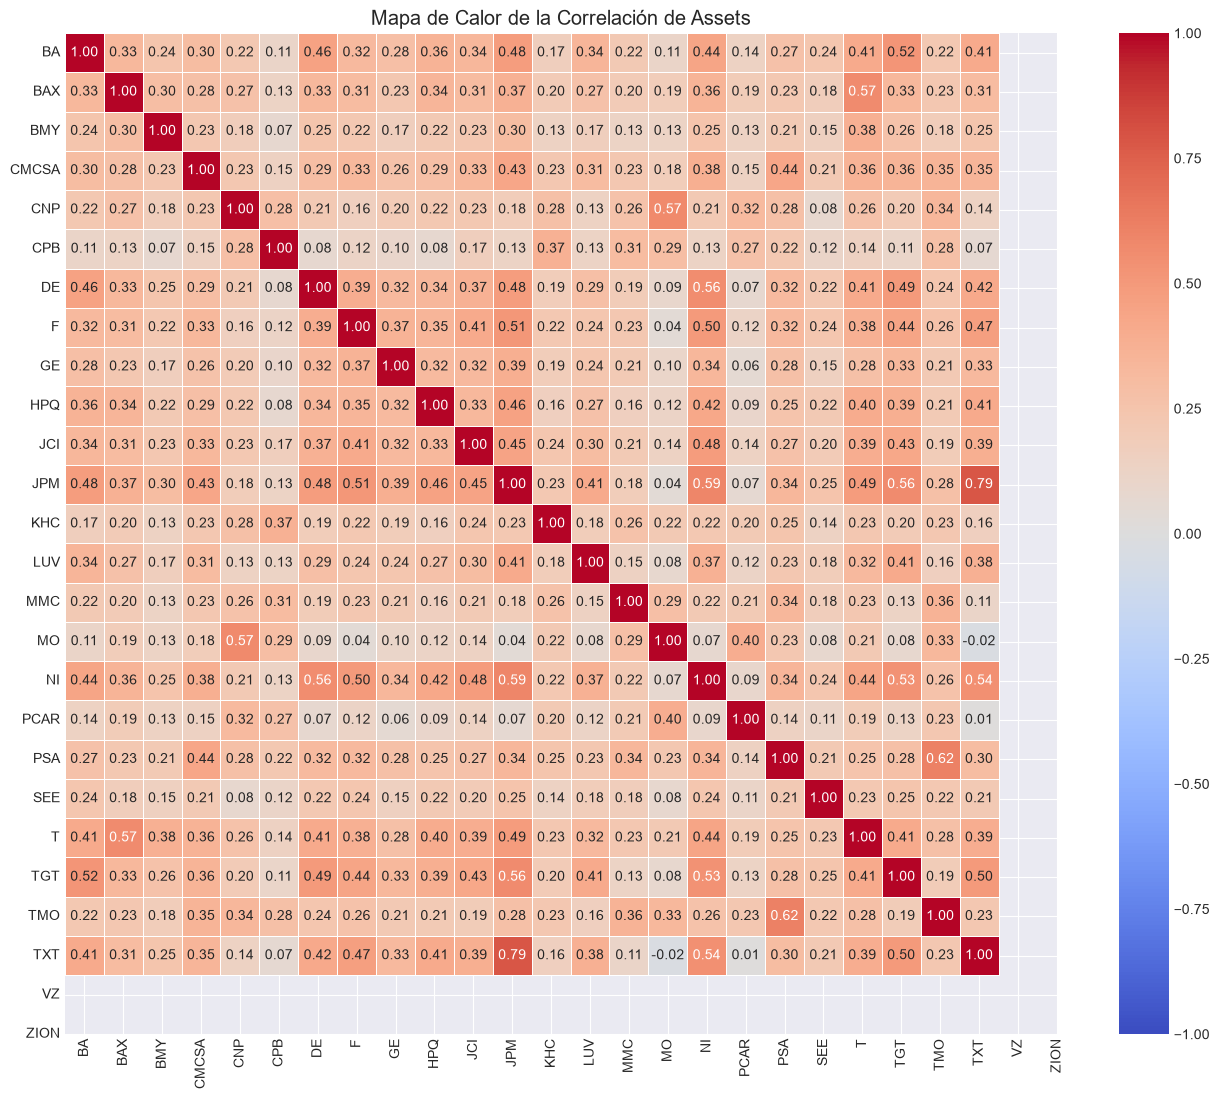

In [34]:
# Correlation matrix
mat_corr = returns.corr().to_numpy()

# Set figure size
plt.figure(figsize=(16, 13))
sns.heatmap(
    mat_corr,
    linewidths=0.5,
    cmap="coolwarm",
    xticklabels=assets,
    yticklabels=assets,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
)
# Añadiendo título
plt.title("Mapa de Calor de la Correlación de Assets")

# Mostrando la gráfica
plt.show()

Plot the assets in risk–return space.

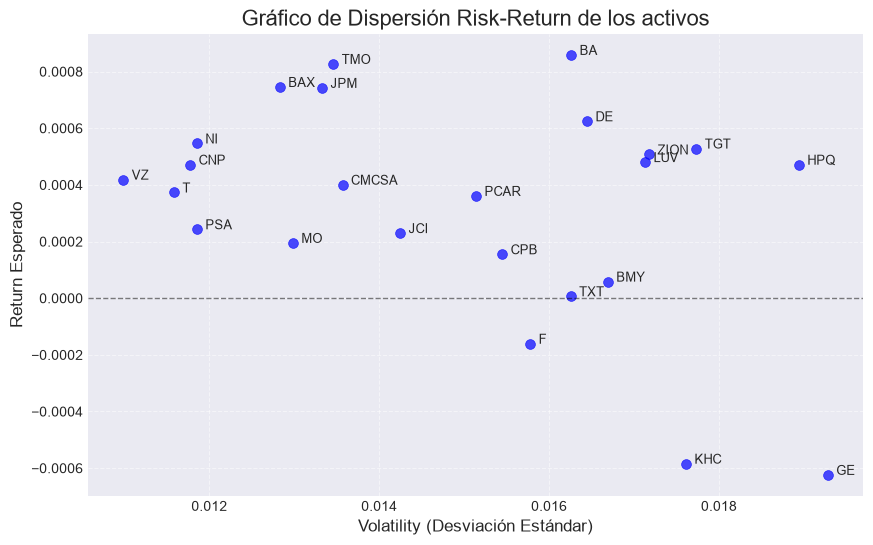

In [36]:
# Set figure size and style
plt.figure(figsize=(10, 6))
plt.style.use("seaborn-v0_8-darkgrid")

plt.scatter(
    np.sqrt(np.diag(matriz_cov)),  # Volatility (standard deviation)
    retornos_esperados,
    color="blue",
    s=50,
    label="Assets",
    alpha=0.7,
)

plt.axhline(0, color="black", lw=1, linestyle="--", alpha=0.5)

# Añadiendo títulos y etiquetas
plt.title("Gráfico de Dispersión Risk-Return de los activos", fontsize=16)
plt.xlabel("Volatility (Desviación Estándar)", fontsize=12)
plt.ylabel("Return Esperado", fontsize=12)

# Añadiendo leyenda con mejor posición
# plt.legend(loc='best')

# Add labels for los activos con un desplazamiento
desplazamiento_x = 0.0001  # Ajusta este valor según sea necesario

for i, asset in enumerate(returns.columns):
    plt.text(
        np.sqrt(matriz_cov[i, i]) + desplazamiento_x,
        retornos_esperados[i],
        asset,
        fontsize=9,
    )


# Mostrando la cuadrícula para mejor lectura
plt.grid(True, linestyle="--", alpha=0.5)

# Mostrar el gráfico
plt.show()

## Exercise 3: Calculating the *Minimum-Risk* Portfolio

Calculate the *minimum-risk* portfolio without short selling.

In [38]:
# TODO Decision variables
pesos = cp.Variable(num_act)

In [39]:
# TODO Constraints
constraints = [
    pesos >= 0,
    cp.sum(pesos) == 1,
]

In [40]:
# TODO Función Objetivo
riesgo = cp.quad_form(pesos, matriz_cov)  # Risk de la cartera (varianza)
objective = cp.Minimize(riesgo)  # Minimizar la varianza

In [41]:
# TODO Define and solve the problem
prob = cp.Problem(objective, constraints)
resultado = prob.solve()

In [42]:
# Check whether an optimal solution was found
if problema.status == cp.OPTIMAL:
    # Results
    pesos_optimos = pesos.value
    print(f"Optimization successful. Optimal value: {resultado}")
else:
    print(f"Could not find una solución óptima. Estado: {problema.status}")
    if problema.status == cp.INFEASIBLE:
        print(
            "El problema es infactible. Las restricciones no pueden satisfacerse simultáneamente."
        )
    elif problema.status == cp.UNBOUNDED:
        print(
            "El problema es no acotado. La función objetivo puede mejorarse indefinidamente."
        )
    elif problema.status == cp.OPTIMAL_INACCURATE:
        print("Se encontró una solución óptima pero con precisión reducida.")
        pesos_optimos = pesos.value

Optimization successful. Optimal value: 4.973144078818063e-05


In [43]:
# Store the return and risk of the minimum-risk portfolio
ret = retornos_esperados.T @ pesos
min_riesgo = np.array([riesgo.value, ret.value])

In [44]:
print(f"The minimum-risk portfolio weights are: \n{pesos.value}")

The minimum-risk portfolio weights are: 
[-8.47060340e-19  8.41940549e-02  4.50147595e-02  2.72188170e-02
  6.67041885e-02  4.03066281e-02  4.08681298e-03  8.27597141e-03
  4.32881222e-03 -7.30736149e-19  4.30964257e-02  6.28038943e-02
 -3.90506812e-20  3.04337670e-02  7.49976612e-02  1.12569920e-01
 -9.62373600e-20  1.68022052e-01  8.22782131e-02  4.71843120e-02
 -5.62721981e-19 -7.51185484e-19  9.26376191e-02  5.84609086e-03]


We can visualize portfolio weights in several ways. One option is a bar chart showing the weight $w_i$ of each asset.

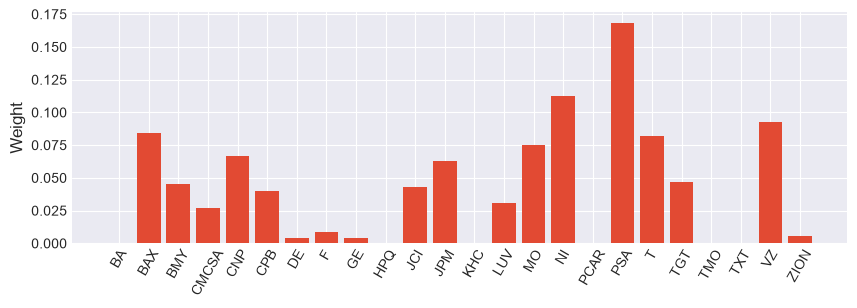

In [46]:
plt.figure(figsize=(10, 3))
plt.bar(range(num_act), pesos.value)
plt.xticks(range(num_act), returns.columns, rotation=60)
plt.ylabel("Weight")
plt.show()

Another option is a pie chart.

CVXPY solves the problem numerically. As a result, some weights can be extremely small; in the previous example, weights of around $10^{-9}$ can be treated as zero.

In [47]:
# Set weights below 10**-4 to zero

pesos_ajustados = np.array([np.round(x, 3) if x > 10**-4 else 0 for x in pesos.value])
pesos_ajustados

array([0.   , 0.084, 0.045, 0.027, 0.067, 0.04 , 0.004, 0.008, 0.004,
       0.   , 0.043, 0.063, 0.   , 0.03 , 0.075, 0.113, 0.   , 0.168,
       0.082, 0.047, 0.   , 0.   , 0.093, 0.006])

In [49]:
activos_filtrados = [
    asset for i, asset in enumerate(returns.columns) if pesos_ajustados[i] > 0
]  # Assets with weights above 10**-4


pesos_filtrados = [x for x in pesos_ajustados if x > 0]  # Weights above 10**-4

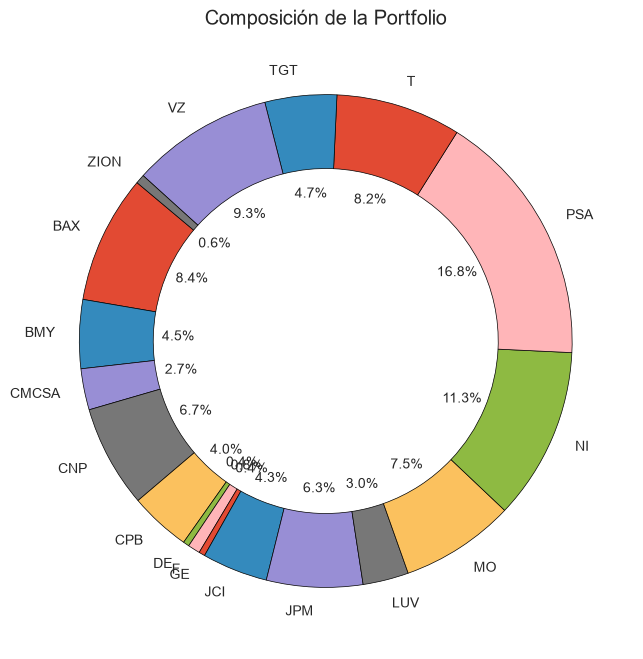

In [50]:
# Create a doughnut chart
plt.figure(figsize=(8, 8))

plt.pie(
    pesos_filtrados,
    labels=activos_filtrados,
    autopct="%1.1f%%",
    startangle=140,
    wedgeprops={"width": 0.3, "edgecolor": "black"},
)

# Add title
plt.title("Composición de la Portfolio")

# Mostrar el gráfico
plt.show()

## Exercise 4: Calculating the *Maximum-Return* Portfolio

Now calculate the portfolio with the highest expected return, assuming short selling is not allowed.

In [51]:
# Decision variables
pesos = cp.Variable(num_act)

In [52]:
# Constraints
constraints = [
    pesos >= 0,  # No shorting
    cp.sum(pesos) == 1,  # Fully invested
]

In [53]:
# Calculate the maximum-return portfolio

ret = retornos_esperados.T @ pesos

objective = cp.Maximize(ret)

prob = cp.Problem(objective, constraints)
resultado = prob.solve()  # solver=cp.ECOS

In [54]:
# Store the return and risk of the maximum-return portfolio
riesgo = cp.quad_form(pesos, matriz_cov)  # Risk de la cartera (varianza)
max_ret = np.array([riesgo.value, ret.value])

Let us visualize the weights again, using both a bar chart and a pie chart.

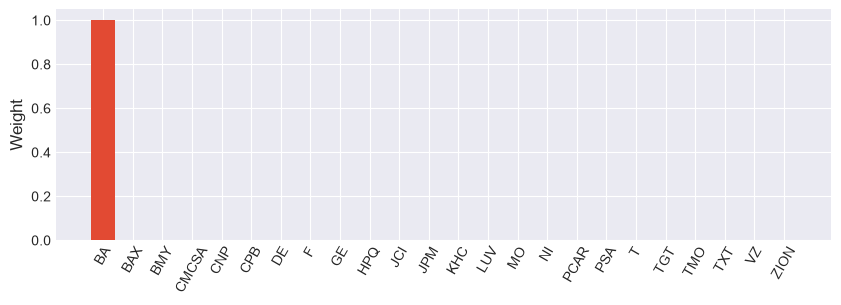

In [56]:
plt.figure(figsize=(10, 3))
plt.bar(range(num_act), pesos.value)
plt.xticks(range(num_act), returns.columns, rotation=60)
plt.ylabel("Weight")
plt.show()

In [58]:
pesos_ajustados = np.array([np.round(x, 3) if x > 10**-4 else 0 for x in pesos.value])

activos_filtrados = [asset for i, asset in enumerate(returns.columns) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x > 0]

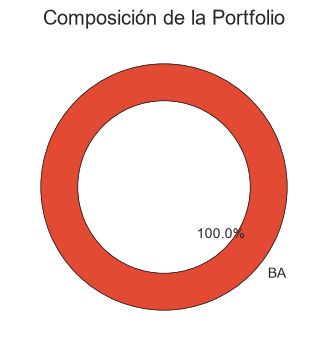

In [59]:
# Create a doughnut chart
plt.figure(figsize=(4, 4))

plt.pie(
    pesos_filtrados,
    labels=activos_filtrados,
    autopct="%1.1f%%",
    startangle=140,
    wedgeprops={"width": 0.3, "edgecolor": "black"},
)

# Add title
plt.title("Composición de la Portfolio")

# Mostrar el gráfico
plt.show()

Now plot these portfolios together with the individual assets.

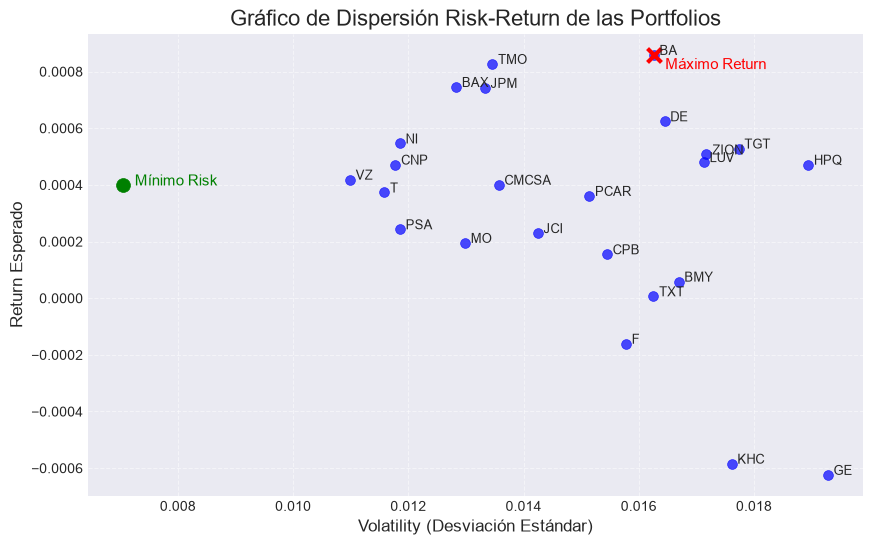

In [61]:
# Set figure size and style
plt.figure(figsize=(10, 6))

# Points for individual assets
plt.scatter(
    np.sqrt(np.diag(matriz_cov)),  # Volatility (standard deviation)
    retornos_esperados,  # Return
    color="blue",
    s=50,
    label="Assets",
    alpha=0.7,
)

# Add labels for los activos con un desplazamiento
desplazamiento_x = 0.0001  # Ajusta este valor según sea necesario
desplazamiento_y = 0.00005  # Ajusta este valor según sea necesario

for i, asset in enumerate(returns.columns):
    plt.text(
        np.sqrt(matriz_cov[i, i]) + desplazamiento_x,
        retornos_esperados[i],
        asset,
        fontsize=9,
    )


# Punto de mínimo riesgo
plt.scatter(
    np.sqrt(min_riesgo[0]),
    min_riesgo[1],
    color="green",
    s=100,
    marker="o",
    label="Mínimo Risk",
)
plt.text(
    np.sqrt(min_riesgo[0]) + 2 * desplazamiento_x,
    min_riesgo[1],
    "Mínimo Risk",
    fontsize=11,
    color="green",
)

# Punto de máximo retorno
plt.scatter(
    np.sqrt(max_ret[0]),
    max_ret[1],
    color="red",
    s=100,
    marker="x",
    linewidths=3,
    label="Máximo Return",
)
plt.text(
    np.sqrt(max_ret[0]) + 2 * desplazamiento_x,
    max_ret[1] - desplazamiento_y,
    "Máximo Return",
    fontsize=11,
    color="red",
)

# Añadiendo títulos y etiquetas
plt.title("Gráfico de Dispersión Risk-Return de las Portfolios", fontsize=16)
plt.xlabel("Volatility (Desviación Estándar)", fontsize=12)
plt.ylabel("Return Esperado", fontsize=12)

# Añadiendo leyenda con mejor posición
# plt.legend(loc='best')

# Mostrando la cuadrícula para mejor lectura
plt.grid(True, linestyle="--", alpha=0.5)

# Mostrar el gráfico
plt.show()

## Exercise 5: *Maximum-Return* Portfolio with a *Maximum Risk Constraint*

Find the portfolio that maximizes expected return without exceeding the specified maximum risk of `0.012`.

In [62]:
# Maximum risk
riesgo_obj = 0.012

In [63]:
# TODO Decision variables
pesos = cp.Variable(num_act)

# TODO Objective function
rentabilidad = cp.Maximize(retornos_esperados.T @ pesos)

# TODO Constraints
riesgo = cp.quad_form(pesos, matriz_cov)  # Variance
constraints = [
    pesos >= 0,
    cp.sum(pesos) == 1,
    riesgo
    <= riesgo_obj
    ** 2,  # "riesgo_obj" es desviación típica (std), de modo que convertimos a varianza
]

# TODO Define and solve the problem
problema = cp.Problem(rentabilidad, constraints)
resultado = problema.solve()

In [64]:
# Check whether an optimal solution was found
if problema.status == cp.OPTIMAL:
    # Results
    pesos_optimos = pesos.value
    print(f"Optimization successful. Optimal value: {resultado}")
else:
    print(f"Could not find una solución óptima. Estado: {problema.status}")
    if problema.status == cp.INFEASIBLE:
        print(
            "El problema es infactible. Las restricciones no pueden satisfacerse simultáneamente."
        )
    elif problema.status == cp.UNBOUNDED:
        print(
            "El problema es no acotado. La función objetivo puede mejorarse indefinidamente."
        )
    elif problema.status == cp.OPTIMAL_INACCURATE:
        print("Se encontró una solución óptima pero con precisión reducida.")
        pesos_optimos = pesos.value

Optimization successful. Optimal value: 0.0008348120744007047


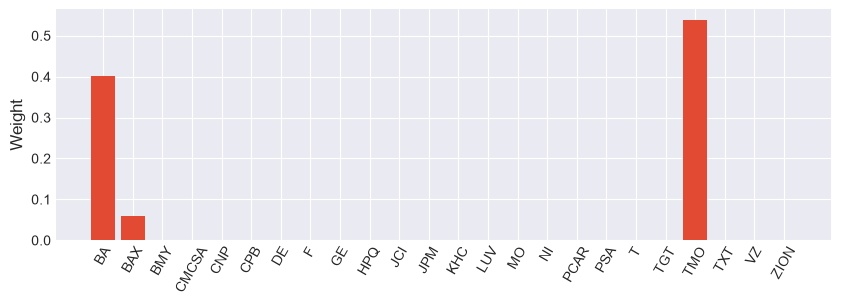

In [66]:
plt.figure(figsize=(10, 3))
plt.bar(range(num_act), pesos.value)
plt.xticks(range(num_act), returns.columns, rotation=60)
plt.ylabel("Weight")
plt.show()

In [68]:
pesos_ajustados = np.array([np.round(x, 3) if x > 10**-4 else 0 for x in pesos.value])

activos_filtrados = [asset for i, asset in enumerate(returns.columns) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x > 0]

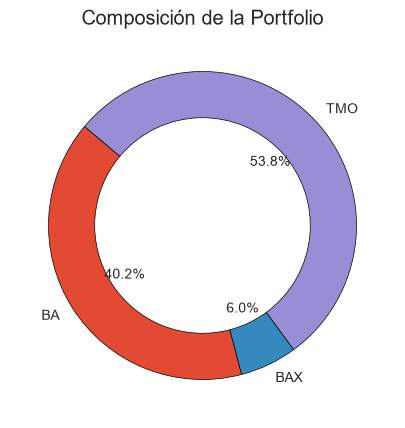

In [69]:
# Create a doughnut chart
plt.figure(figsize=(5, 5))

plt.pie(
    pesos_filtrados,
    labels=activos_filtrados,
    autopct="%1.1f%%",
    startangle=140,
    wedgeprops={"width": 0.3, "edgecolor": "black"},
)

# Add title
plt.title("Composición de la Portfolio")

# Mostrar el gráfico
plt.show()

Let us plot the portfolio alongside the individual assets.

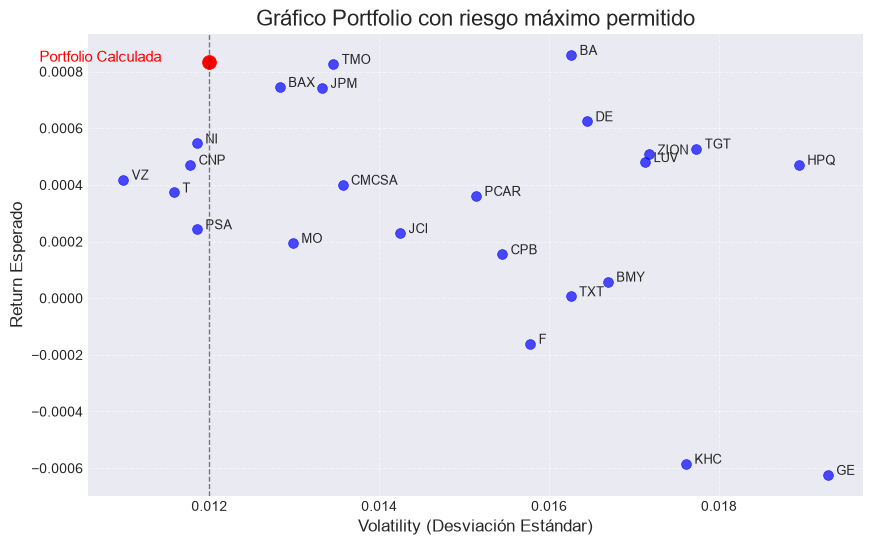

In [71]:
# Set figure size and style
plt.figure(figsize=(10, 6))

# Points for individual assets
plt.scatter(
    np.sqrt(np.diag(matriz_cov)),  # Volatility (standard deviation)
    retornos_esperados,
    color="blue",
    s=50,
    alpha=0.7,
)


# Add labels for los activos con un desplazamiento
desplazamiento_x = 0.0001  # Ajusta este valor según sea necesario
desplazamiento_y = 0.00003  # Ajusta este valor según sea necesario

for i, asset in enumerate(returns.columns):
    plt.text(
        np.sqrt(matriz_cov[i, i]) + desplazamiento_x,
        retornos_esperados[i],
        asset,
        fontsize=9,
    )


plt.scatter(
    np.sqrt(riesgo.value),  # Volatility (standard deviation)
    resultado,
    color="red",
    s=100,
    marker="o",
)
plt.text(
    np.sqrt(riesgo.value) - 20 * desplazamiento_x,
    resultado,
    "Portfolio Calculada",
    fontsize=11,
    color="red",
)

plt.axvline(riesgo_obj, color="black", lw=1, linestyle="--", alpha=0.5)


# Añadiendo títulos y etiquetas
plt.title("Gráfico Portfolio con riesgo máximo permitido", fontsize=16)
plt.xlabel("Volatility (Desviación Estándar)", fontsize=12)
plt.ylabel("Return Esperado", fontsize=12)

# Añadiendo leyenda con mejor posición
# plt.legend(loc='best')

# Mostrando la cuadrícula para mejor lectura
plt.grid(True, linestyle="--", alpha=0.5)

# Mostrar el gráfico
plt.show()

## Exercise 6: Calculating the *Maximum-Return Portfolio for Different Risk-Tolerance Levels*

Investors have different levels of risk tolerance, reflected in their risk aversion. Recall the Markowitz objective:

$$\underset{w}{\max} f(w)=w^T\mu-\lambda w^T\Sigma w$$

Now we will calculate optimal portfolios for different levels of risk aversion.

- The parameter $\Large \boldsymbol{\lambda}$ represents the investor's risk aversion.
- It must satisfy $\Large \boldsymbol{\lambda}\geq 0$.
- A low $\Large \boldsymbol{\lambda}$ indicates greater willingness to take risk in pursuit of higher returns.
- A high $\Large \boldsymbol{\lambda}$ indicates a preference for safer investments, even at lower expected returns.
- The parameter $\Large \boldsymbol{\lambda}$ determines the trade-off between risk and expected return.

Note: This example is based on the [CVXPY Documentation](https://www.cvxpy.org/).

In [72]:
# Decision variables
pesos = cp.Variable(num_act)

# Risk-aversion parameter
gamma = cp.Parameter(
    nonneg=True
)  # Do not use lambda as a variable name, since it is a Python keyword

ret = retornos_esperados.T @ pesos

riesgo = cp.quad_form(pesos, matriz_cov)  # Variance

We define the **objective function**:

- The objective seeks to maximize returns while penalizing risk.
- Subtracting risk multiplied by the gamma parameter favors lower-risk portfolios at a given expected return.
- A higher gamma indicates greater risk aversion and prioritizes lower risk, even if expected returns are lower.

In [73]:
objetivo = cp.Maximize(ret - gamma * riesgo)

In [74]:
# Constraints and objective function
constraints = [pesos >= 0, cp.sum(pesos) == 1]

prob = cp.Problem(objetivo, constraints)

In [75]:
# Solve for different gamma values
num_sim = 100
riesgos_res = np.zeros(num_sim)
retornos_res = np.zeros(num_sim)
pesos_res = np.zeros((num_sim, num_act))
gamma_vals = np.logspace(-2, 3, num=num_sim)

for i in range(num_sim):
    gamma.value = gamma_vals[i]
    prob.solve()
    retornos_res[i] = ret.value
    riesgos_res[i] = cp.sqrt(riesgo).value
    pesos_res[i, :] = pesos.value

In [76]:
pesos_res.shape

(100, 24)

Now let us plot all the results.

<>:46: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:51: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:65: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:70: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:84: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:89: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:46: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences wil

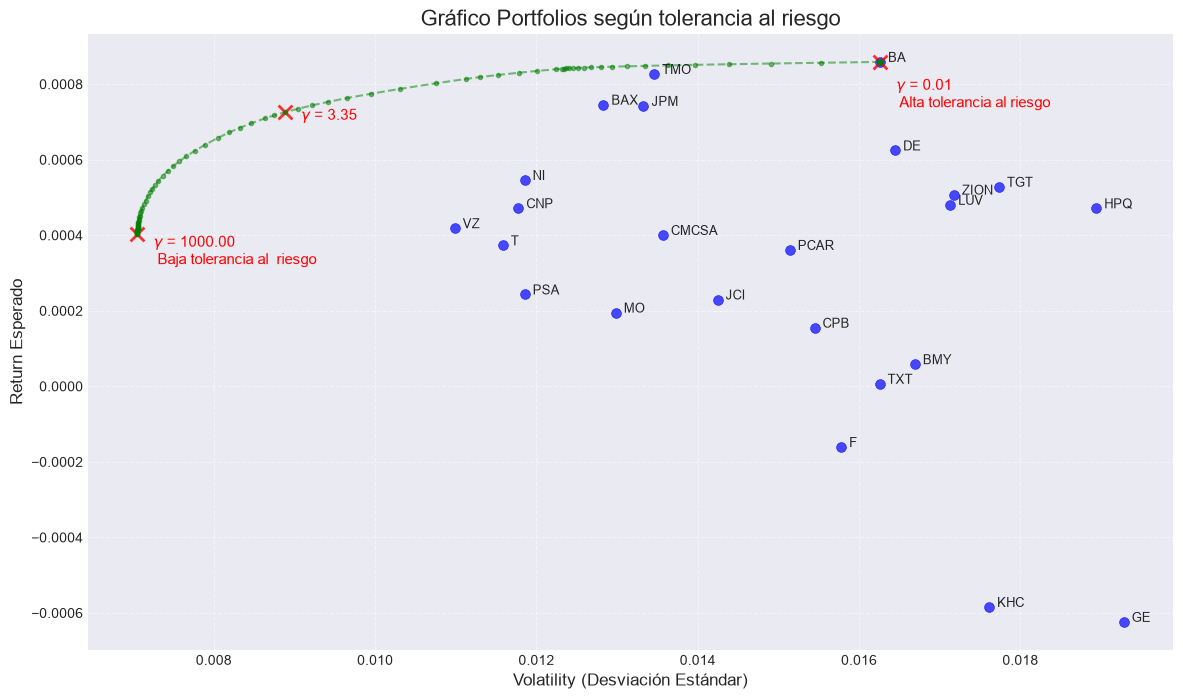

In [78]:
# Set figure size and style
plt.figure(figsize=(14, 8))
plt.style.use("seaborn-v0_8-darkgrid")

# Points for individual assets
plt.scatter(
    np.sqrt(np.diag(matriz_cov)),  # Volatility (standard deviation)
    retornos_esperados,
    color="blue",
    s=50,
    label="Assets",
    alpha=0.7,
)

# Add labels for los activos con un desplazamiento
desplazamiento_x = 0.0001  # Ajusta este valor según sea necesario
desplazamiento_y = 0.00002  # Ajusta este valor según sea necesario

for i, asset in enumerate(returns.columns):
    plt.text(
        np.sqrt(matriz_cov[i, i]) + desplazamiento_x,
        retornos_esperados[i],
        asset,
        fontsize=9,
    )

# Portfolios en la frontera eficiente.
plt.plot(
    riesgos_res,
    retornos_res,
    ".--",
    color="green",
    label="Efficient Frontier",
    alpha=0.5,
)

# Última cartera en la frontera eficiente.
plt.scatter(
    riesgos_res[num_sim - 1],
    retornos_res[num_sim - 1],
    color="red",
    s=100,
    marker="x",
    linewidths=2,
    alpha=0.8,
    label=f"$\gamma$ = {gamma_vals[num_sim-1]:.2f}",
)
plt.text(
    riesgos_res[num_sim - 1] + 2 * desplazamiento_x,
    retornos_res[num_sim - 1] - 4 * desplazamiento_y,
    f"$\gamma$ = {gamma_vals[num_sim-1]:.2f} \n Baja tolerancia al  riesgo",
    fontsize=11,
    color="red",
)

# Portfolio intermedia en la frontera eficiente.
plt.scatter(
    riesgos_res[int(num_sim / 2)],
    retornos_res[int(num_sim / 2)],
    color="red",
    s=100,
    marker="x",
    linewidths=2,
    alpha=0.8,
    label=f"$\gamma$ = {gamma_vals[int(num_sim/2)]:.2f}",
)
plt.text(
    riesgos_res[int(num_sim / 2)] + 2 * desplazamiento_x,
    retornos_res[int(num_sim / 2)] - desplazamiento_y,
    f"$\gamma$ = {gamma_vals[int(num_sim/2)]:.2f}",
    fontsize=11,
    color="red",
)

# Primera cartera en la frontera eficiente.
plt.scatter(
    riesgos_res[int(0)],
    retornos_res[int(0)],
    color="red",
    s=100,
    marker="x",
    linewidths=2,
    alpha=0.8,
    label=f"$\gamma$ = {gamma_vals[int(0)]:.2f}",
)
plt.text(
    riesgos_res[int(0)] + 2 * desplazamiento_x,
    retornos_res[int(0)] - 6 * desplazamiento_y,
    f"$\gamma$ = {gamma_vals[0]:.2f}\n Alta tolerancia al riesgo",
    fontsize=11,
    color="red",
)

# Añadiendo títulos y etiquetas
plt.title("Gráfico Portfolios según tolerancia al riesgo", fontsize=16)
plt.xlabel("Volatility (Desviación Estándar)", fontsize=12)
plt.ylabel("Return Esperado", fontsize=12)

# Añadiendo leyenda con mejor posición
# plt.legend(loc='best')

# Mostrando la cuadrícula para mejor lectura
plt.grid(True, linestyle="--", alpha=0.5)

# Mostrar el gráfico
plt.show()

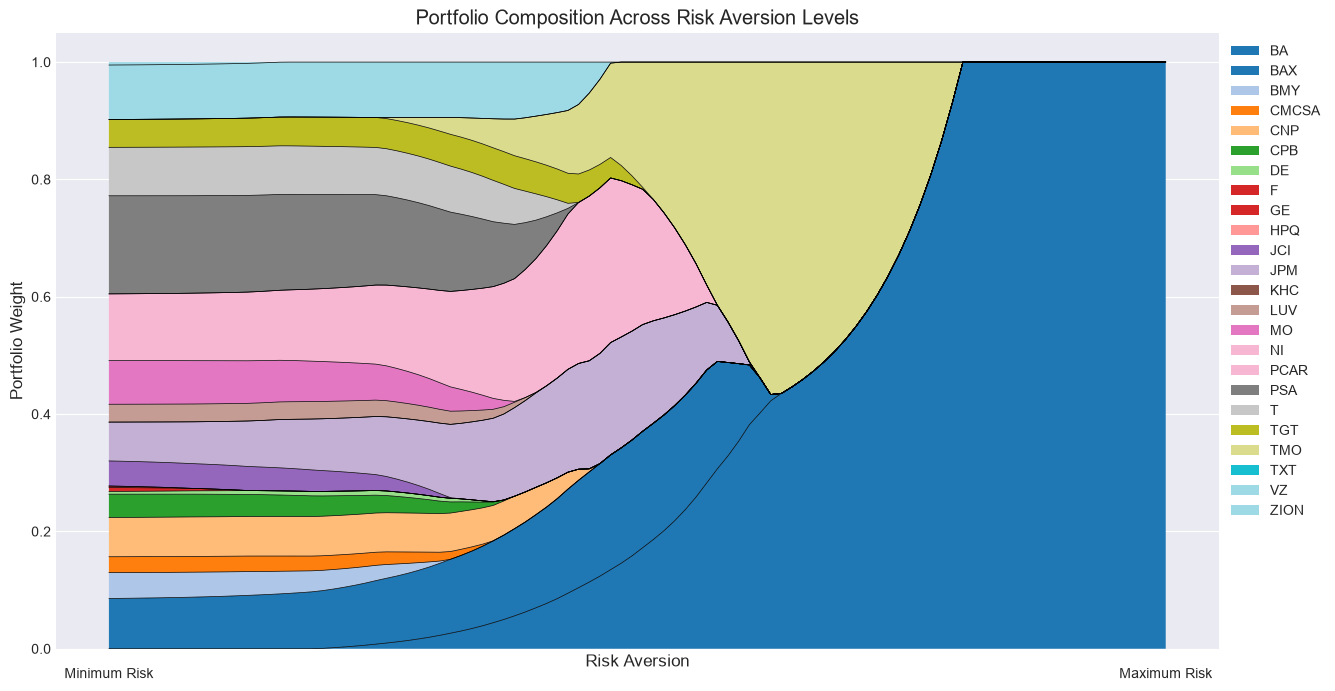

In [94]:
# Number of portfolios and assets
num_sim, num_act = pesos_res.shape

# Stock names (same order as in the returns DataFrame)
assets = returns.columns

# Colors for each stock
colores = plt.get_cmap("tab20", num_act)(np.arange(num_act))

# Horizontal axis: different risk-aversion levels
x = np.arange(num_sim)

plt.figure(figsize=(15, 8))

# Stacked area chart of portfolio weights
plt.stackplot(
    x,
    pesos_res.T,
    colors=colores,
    labels=assets
)

# Add black lines separating the assets
for i in range(num_act - 1):
    plt.plot(
        x,
        pesos_res[:, :i+1].sum(axis=1),
        color="black",
        linewidth=0.5
    )

# Reverse the horizontal axis
plt.gca().invert_xaxis()

# Labels and title
plt.xlabel("Risk Aversion")
plt.ylabel("Portfolio Weight")
plt.title("Portfolio Composition Across Risk Aversion Levels")

# Identify low-risk and high-risk portfolios
plt.text(num_sim - 1, -0.05, "Minimum Risk", ha="center")
plt.text(0, -0.05, "Maximum Risk", ha="center")

# Legend
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.xticks([])

plt.show()


## Exercise 7: Portfolios with a Maximum Weight per Asset

Calculate the portfolio with the highest possible return, ensuring that no individual asset exceeds a specified portfolio weight.

In [81]:
# Decision variables
pesos = cp.Variable(num_act)

# Objective function
rentabilidad = cp.Maximize(retornos_esperados.T @ pesos)

In [82]:
# TODO restricciones

max_inv = 0.1  # Maximum investment in one asset

constraints = [pesos >= 0, cp.sum(pesos) == 1, pesos <= max_inv]

In [83]:
# TODO Define and solve the problem.

prob = cp.Problem(rentabilidad, constraints)


resultado = prob.solve()  # solver=cp.ECOS

In [85]:
pesos_ajustados = np.array([np.round(x, 3) if x > 10**-4 else 0 for x in pesos.value])

activos_filtrados = [asset for i, asset in enumerate(returns.columns) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x > 0]

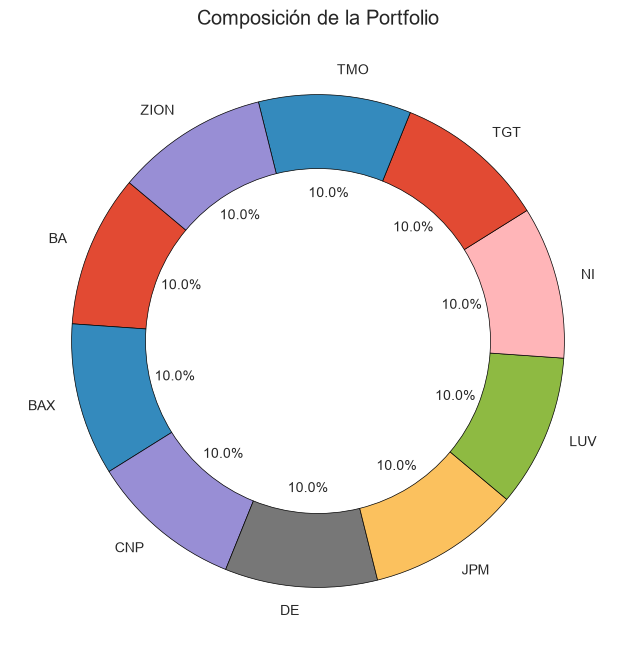

In [86]:
# Create a doughnut chart
plt.figure(figsize=(8, 8))

plt.pie(
    pesos_filtrados,
    labels=activos_filtrados,
    autopct="%1.1f%%",
    startangle=140,
    wedgeprops={"width": 0.3, "edgecolor": "black"},
)

# Add title
plt.title("Composición de la Portfolio")

# Mostrar el gráfico
plt.show()

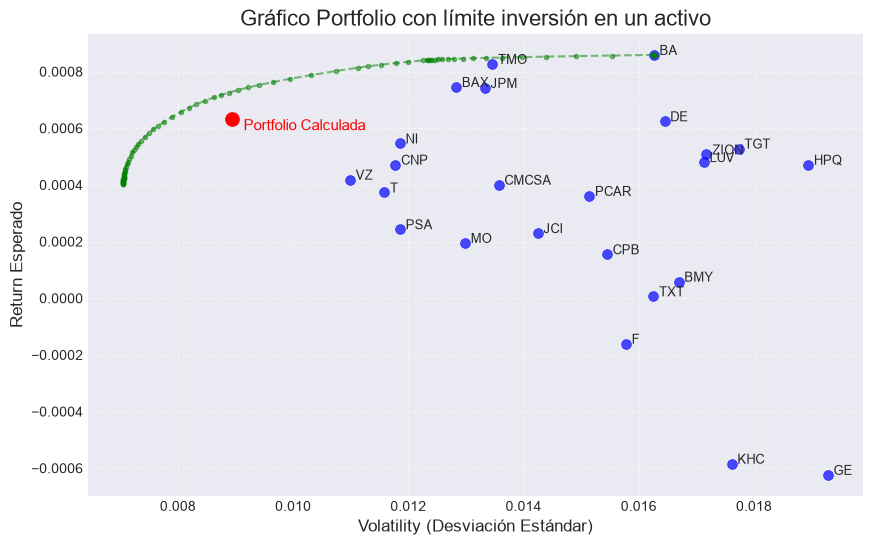

In [88]:
# Set figure size and style
plt.figure(figsize=(10, 6))

# Points for individual assets
plt.scatter(
    np.sqrt(np.diag(matriz_cov)),
    retornos_esperados,
    color="blue",
    s=50,
    label="Assets",
    alpha=0.7,
)

# Add labels for los activos con un desplazamiento
desplazamiento_x = 0.0001  # Ajusta este valor según sea necesario
desplazamiento_y = 0.00002  # Ajusta este valor según sea necesario

for i, asset in enumerate(returns.columns):
    plt.text(
        np.sqrt(matriz_cov[i, i]) + desplazamiento_x,
        retornos_esperados[i],
        asset,
        fontsize=9,
    )

# Portfolios en la frontera eficiente.
plt.plot(
    riesgos_res,
    retornos_res,
    ".--",
    color="green",
    label="Efficient Frontier",
    alpha=0.5,
)

# Portfolio calculada.
plt.scatter(
    np.sqrt(cp.quad_form(pesos, matriz_cov).value),
    resultado,
    color="red",
    s=100,
    marker="o",
    label="Portfolio Calculada",
)
plt.text(
    np.sqrt(cp.quad_form(pesos, matriz_cov).value) + 2 * desplazamiento_x,
    resultado - 2 * desplazamiento_y,
    "Portfolio Calculada",
    fontsize=11,
    color="red",
)

# Añadiendo títulos y etiquetas
plt.title("Gráfico Portfolio con límite inversión en un activo", fontsize=16)
plt.xlabel("Volatility (Desviación Estándar)", fontsize=12)
plt.ylabel("Return Esperado", fontsize=12)

# Añadiendo leyenda con mejor posición
# plt.legend(loc='best')

# Mostrando la cuadrícula para mejor lectura
plt.grid(True, linestyle="--", alpha=0.5)

# Mostrar el gráfico
plt.show()

## Exercise 8: Portfolios with Constraints on the Minimum Number of Assets, Minimum Investment per Asset, and Expected Return

Find a portfolio that exceeds a specified expected return while holding at least a minimum number of assets, thereby promoting diversification.

In [89]:
pesos = cp.Variable(num_act)
riesgo = cp.quad_form(pesos, matriz_cov)
factor = 0.8
minimum_return = factor * retornos_esperados.max()
ret = retornos_esperados.T @ pesos

constraints = [cp.sum(pesos) == 1, pesos >= 0, ret >= minimum_return]

Now define the constraints that enforce a minimum number of assets:

* Define `min_act = 12` so that the portfolio contains at least 12 assets.

* Define `peso_minimo = 0.05` as the minimum weight assigned to a selected asset.

In [90]:
min_act = 12  # Número mínimo de activos de la cartera
peso_minimo = 0.05  # Porcentaje mínimo que puedes invertir en un activo

**Including at least `min_act` assets**:

- Binary selection variables (`selection`) are used: a value of 1 means the asset is included in the portfolio, and 0 means it is excluded.
- `cp.sum(selection) >= min_act` ensures that at least `min_act` assets are included.

In [91]:
selection = cp.Variable(num_act, boolean=True)
constraints.append(cp.sum(selection) >= min_act)

**Linking selection variables to portfolio weights**:

- `pesos <= selection` links each weight to its corresponding selection variable.
- `pesos >= peso_minimo * selection` imposes a minimum weight on each selected asset.
  - If an asset is not selected (`selection[i] = 0`), its weight (`pesos[i]`) is zero, so it does not affect the portfolio.
  - If an asset is selected (`selection[i] = 1`), its weight can be positive, allowing it to be included.
  - The second constraint ensures that a selected asset has a weight of at least `peso_minimo`.

This formulation ensures that only selected assets contribute to the portfolio.

In [92]:
constraints.append(pesos <= selection)
constraints.append(pesos >= peso_minimo * selection)

In [97]:
problem = cp.Problem(cp.Minimize(riesgo), constraints)

resultado = problem.solve(
    solver=cp.SCIP
)  # Specify the solver because the model contains binary variables

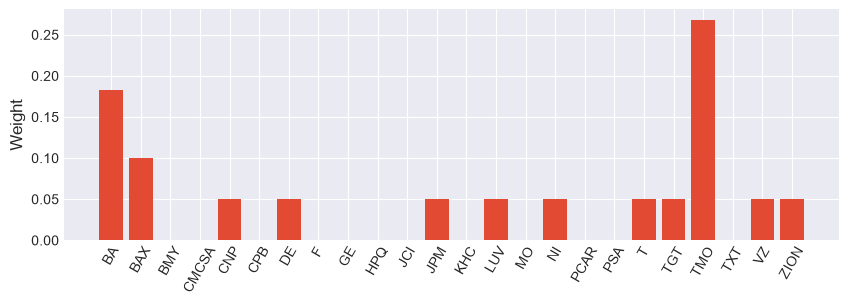

In [98]:
plt.figure(figsize=(10, 3))
plt.bar(range(num_act), pesos.value)
plt.xticks(range(num_act), assets, rotation=60)
plt.ylabel("Weight")
plt.show()

In [99]:
pesos_ajustados = np.array([np.round(x, 3) if x > 10**-4 else 0 for x in pesos.value])

activos_filtrados = [asset for i, asset in enumerate(assets) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x > 0]

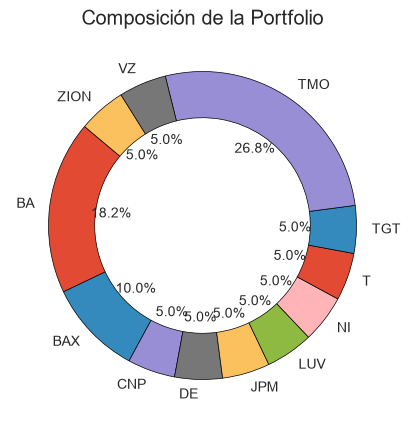

In [100]:
# Create a doughnut chart
plt.figure(figsize=(5, 5))

plt.pie(
    pesos_filtrados,
    labels=activos_filtrados,
    autopct="%1.1f%%",
    startangle=140,
    wedgeprops={"width": 0.3, "edgecolor": "black"},
)

# Add title
plt.title("Composición de la Portfolio")

# Mostrar el gráfico
plt.show()

In [101]:
# Calculate portfolio return
ret = (retornos_esperados.T @ pesos).value

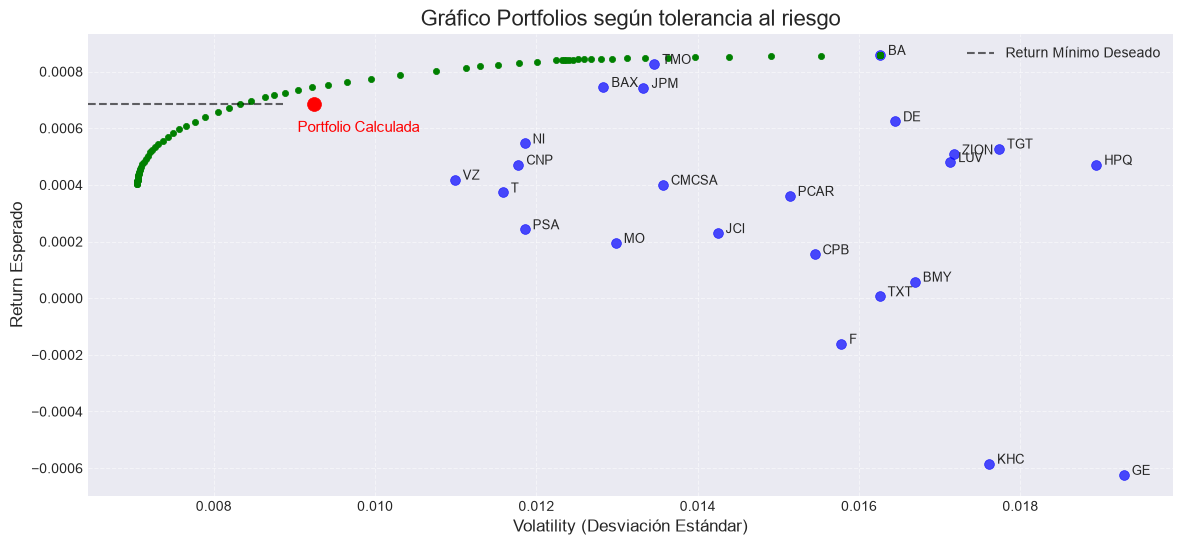

In [102]:
# Set figure size and style
plt.figure(figsize=(14, 6))

# Points for individual assets
plt.scatter(
    np.sqrt(np.diag(matriz_cov)), retornos_esperados, color="blue", s=50, alpha=0.7
)

# Add labels for los activos con un desplazamiento
desplazamiento_x = 0.0001  # Ajusta este valor según sea necesario
desplazamiento_y = 0.0001  # Ajusta este valor según sea necesario

for i, asset in enumerate(assets):
    plt.text(
        np.sqrt(matriz_cov[i, i]) + desplazamiento_x,
        retornos_esperados[i],
        asset,
        fontsize=9,
    )

# plt.scatter(riesgos_res, retornos_res, color='green', s=20, marker='o')#,  alpha=0.3)

plt.axhline(
    xmin=0,
    xmax=0.18,
    y=minimum_return,
    color="black",
    linestyle="--",
    label="Return Mínimo Deseado",
    alpha=0.6,
)


plt.scatter(np.sqrt(resultado), ret, color="red", s=100, marker="o")
plt.text(
    np.sqrt(resultado) - 2 * desplazamiento_x,
    ret - desplazamiento_y,
    "Portfolio Calculada",
    fontsize=11,
    color="red",
)

plt.scatter(riesgos_res, retornos_res, color="green", s=20, marker="o")

# Añadiendo títulos y etiquetas
plt.title("Gráfico Portfolios según tolerancia al riesgo", fontsize=16)
plt.xlabel("Volatility (Desviación Estándar)", fontsize=12)
plt.ylabel("Return Esperado", fontsize=12)

# Añadiendo leyenda con mejor posición
plt.legend(loc="best")

# Mostrando la cuadrícula para mejor lectura
plt.grid(True, linestyle="--", alpha=0.5)

# Mostrar el gráfico
plt.show()